# Notebook 3 — Opening Free Energies (ΔG_open)

Exchange rates tell us *how fast* deuterium incorporates. Free energies tell us *how stable*
each region is. Under the **EX2 regime** (the standard for folded proteins at physiological
conditions), the two are related by:

$$\Delta G_\mathrm{open} = -RT \ln K_\mathrm{op}, \qquad K_\mathrm{op} = \frac{k_\mathrm{HX}}{k_\mathrm{intr} - k_\mathrm{HX}}$$

where $k_\mathrm{intr}$ is the **intrinsic chemical exchange rate** of the residue in an
unstructured peptide — a known function of sequence, pH, and temperature (Milne 2003).

This notebook covers:
1. Computing Milne intrinsic rates
2. The regression correction that improves accuracy
3. Per-residue ΔG_open with full posterior uncertainty
4. Net-charge correction
5. Interpreting the stability landscape

In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import matplotlib.pyplot as plt

import hdxrate
from hdxrate import MCMCConfig, process_single_protein
from hdxrate import milne_intrinsic_rates
from hdxrate.testing import generate_mock_rows

print('hdxrate loaded from:', hdxrate.__file__)

hdxrate loaded from: /Users/allan/Work/Claude/hdxrate_v2.0/notebooks/../src/hdxrate/__init__.py


## 0. Regenerate data and run inference

Identical setup to Notebooks 1–2 so this notebook is self-contained.
The inference cell takes ~1–3 min; the free-energy computation is instant.

In [2]:
SEQUENCE          = "ACDEFGHIKLMNQRSTVWY"
TIMEPOINTS        = np.array([10., 60., 300., 1800., 7200., 86400.])
N_EXCHANGEABLE    = sum(1 for i, aa in enumerate(SEQUENCE) if i >= 2 and aa != 'P')
TRUE_LOG_RATES    = np.linspace(-10, -3, N_EXCHANGEABLE)

PH               = 6.0
CHARGE           = 3
D2O_FRACTION     = 0.95
D2O_PURITY       = 0.95
TEMPERATURE      = 295.0
TRUE_BACKEXCHANGE = 0.20
NUM_BINS         = 30

rows = generate_mock_rows(
    sequence=SEQUENCE, true_log_rates=TRUE_LOG_RATES,
    timepoints=TIMEPOINTS, pHs=[PH], charge=CHARGE,
    d2o_fraction=D2O_FRACTION, d2o_purity=D2O_PURITY,
    temperature=TEMPERATURE, true_backexchange=TRUE_BACKEXCHANGE,
    noise_sigma=0.01, num_bins=NUM_BINS, rng_seed=42,
)

result = process_single_protein(
    rows=rows,
    mcmc_config=MCMCConfig(num_chains=2, num_warmup=150, num_samples=300, rng_seed=0),
    compute_free_energies=True,
)
print(f"Inference done. RMSE = {result.rmse_total:.4f}")

  0%|          | 0/450 [00:00<?, ?it/s]

  0%|          | 0/450 [00:00<?, ?it/s]

Inference done. RMSE = 0.0075


## 1. Milne intrinsic rates

The **Milne model** predicts the exchange rate of each backbone NH in a fully unstructured
peptide, accounting for:
- Acid-catalysed, base-catalysed, and water-catalysed pathways
- Nearest-neighbour effects (left and right residue identity affect rate by up to 10×)
- Arrhenius temperature correction
- pH and D₂O isotope effect

These are the *reference* rates: if a residue exchanges at exactly its intrinsic rate,
it is fully exposed and unstructured (ΔG_open = 0). Slower exchange means it is protected
by structure (positive ΔG_open = more stable).

Sequence length      : 19
Exchangeable residues: 18
Intrinsic rate range : 4.16e-03 – 1.09e+02 s⁻¹


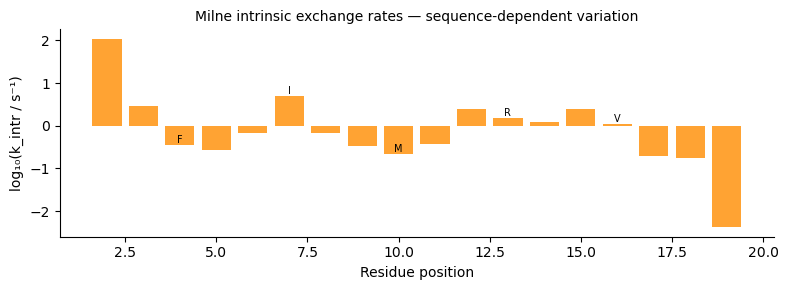

In [5]:
# Compute intrinsic rates for our sequence
intr_rates = milne_intrinsic_rates(
    sequence    = SEQUENCE,
    temperature = TEMPERATURE,
    pH          = PH,
    d2o_purity  = D2O_PURITY,
    d2o_fraction= D2O_FRACTION,
)

# intr_rates has len(SEQUENCE) entries; 0.0 for the first 2 residues and prolines
exchangeable_mask = intr_rates > 0
intr_active = intr_rates[exchangeable_mask]

print(f"Sequence length      : {len(SEQUENCE)}")
print(f"Exchangeable residues: {exchangeable_mask.sum()}")
print(f"Intrinsic rate range : {intr_active.min():.2e} – {intr_active.max():.2e} s⁻¹")

fig, ax = plt.subplots(figsize=(8, 3))
residue_idx = np.where(exchangeable_mask)[0]
ax.bar(residue_idx + 1, np.log10(intr_active), color='darkorange', alpha=0.8)
ax.set_xlabel('Residue position', fontsize=10)
ax.set_ylabel('log₁₀(k_intr / s⁻¹)', fontsize=10)
ax.set_title('Milne intrinsic exchange rates — sequence-dependent variation', fontsize=10)

# Annotate a few residues
for pos, res in zip(residue_idx, list(SEQUENCE)[2:]):
    if pos % 3 == 0:
        ax.text(pos + 1, np.log10(intr_rates[pos]) + 0.05, res, ha='center', fontsize=7)

ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

## 2. Regression correction

Absolute intrinsic rates carry systematic errors from the Milne model. The **regression
correction** (Skinner et al. 2012) rescales intrinsics using the spread of the measured
rates as a guide:

$$\log k_\mathrm{intr,i}^\mathrm{corr} = \mathrm{median}(\log k_\mathrm{intr}) +
0.38 \cdot z_i \cdot \mathrm{std}(\log k_\mathrm{intr})$$

where $z_i$ is the z-score of the *measured* log-rate. The slope 0.38 empirically reduces
systematic bias when the measured rates span a narrower range than the intrinsics.

In [23]:
raw_intr.shape, reg_intr.shape

((18,), (17,))

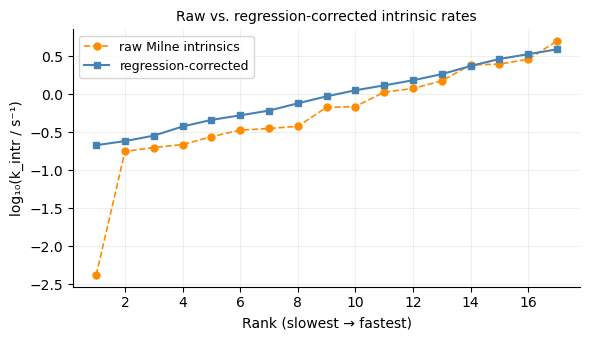

Raw intrinsic range      : -2.38 – 0.70
Corrected intrinsic range: -0.67 – 0.59


In [25]:
fe = result.free_energy

raw_intr = fe.intrinsic_rates[2:] #[fe.intrinsic_rates > 0]   # remove zeros
reg_intr = fe.reg_intrinsic_rates    # already active only

fig, ax = plt.subplots(figsize=(6, 3.5))

x = np.arange(1, len(reg_intr) + 1)
ax.plot(x, np.log10(np.sort(raw_intr)), 'o--', ms=5, lw=1.2,
        color='darkorange', label='raw Milne intrinsics')
ax.plot(x, np.log10(reg_intr), 's-', ms=5, lw=1.5,
        color='steelblue', label='regression-corrected')

ax.set_xlabel('Rank (slowest → fastest)', fontsize=10)
ax.set_ylabel('log₁₀(k_intr / s⁻¹)', fontsize=10)
ax.set_title('Raw vs. regression-corrected intrinsic rates', fontsize=10)
ax.legend(fontsize=9)
ax.spines[['top','right']].set_visible(False)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Raw intrinsic range      : {np.log10(raw_intr.min()):.2f} – {np.log10(raw_intr.max()):.2f}")
print(f"Corrected intrinsic range: {np.log10(reg_intr.min()):.2f} – {np.log10(reg_intr.max()):.2f}")

## 3. Per-residue ΔG_open with posterior uncertainty

`FreeEnergyResult.dG_mean` gives the ΔG computed from the posterior *mean* rates.
`FreeEnergyResult.dG_samples` (shape S × N_active) gives ΔG for every MCMC sample,
propagating the full rate uncertainty through to free energy.

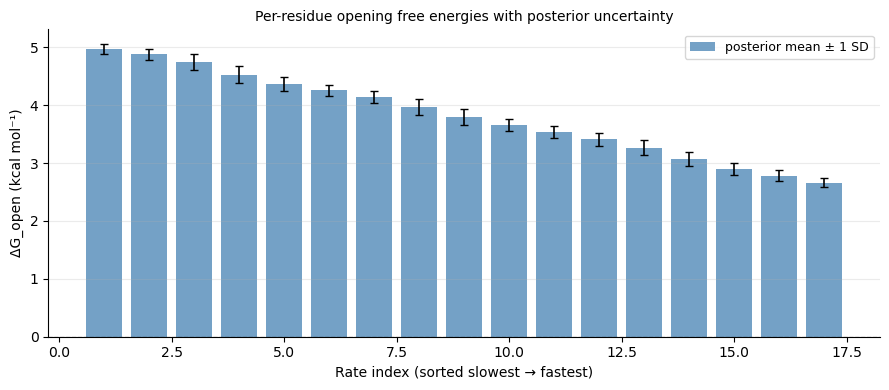

In [26]:
dG_mean    = fe.dG_mean           # (N_active,)
dG_samples = fe.dG_samples        # (S, N_active)
dG_std     = np.std(dG_samples, axis=0)

n_active = len(dG_mean)
x = np.arange(1, n_active + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x, dG_mean, yerr=dG_std, color='steelblue', alpha=0.75,
       error_kw=dict(ecolor='black', lw=1.2, capsize=3),
       label='posterior mean ± 1 SD')
ax.axhline(0, color='black', lw=0.8, ls='--')
ax.set_xlabel('Rate index (sorted slowest → fastest)', fontsize=10)
ax.set_ylabel('ΔG_open (kcal mol⁻¹)', fontsize=10)
ax.set_title('Per-residue opening free energies with posterior uncertainty', fontsize=10)
ax.legend(fontsize=9)
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Full posterior uncertainty — violin plot

The violin plot shows the complete shape of the ΔG posterior for each residue,
not just ±1 SD. Asymmetric or multi-modal violins indicate non-Gaussian posteriors
(common for residues near k_meas ≈ k_intr, where K_op diverges).

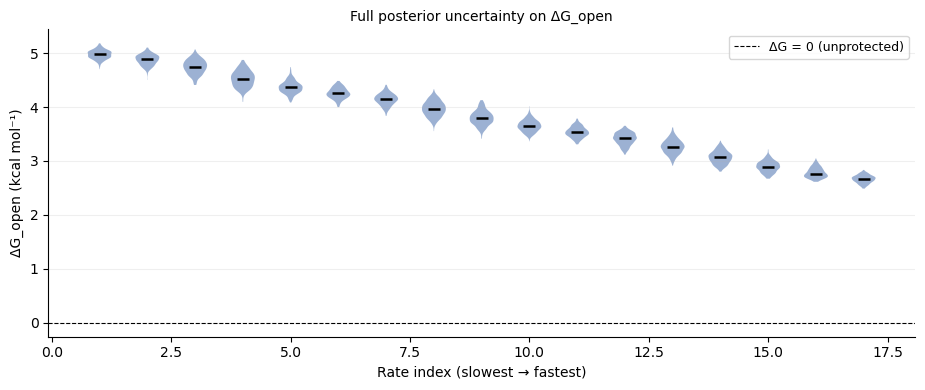

In [27]:
# Filter to finite dG samples only
finite_mask = np.isfinite(dG_mean)
dG_samples_finite = dG_samples[:, finite_mask]
n_finite = dG_samples_finite.shape[1]

fig, ax = plt.subplots(figsize=(max(6, n_finite * 0.55), 4))
positions = np.arange(1, n_finite + 1)
parts = ax.violinplot(dG_samples_finite, positions=positions,
                      showmedians=True, showextrema=False)

for pc in parts['bodies']:
    pc.set_facecolor('#4C72B0')
    pc.set_alpha(0.55)
parts['cmedians'].set_color('black')
parts['cmedians'].set_linewidth(1.8)

ax.axhline(0, color='black', lw=0.8, ls='--', label='ΔG = 0 (unprotected)')
ax.set_xlabel('Rate index (slowest → fastest)', fontsize=10)
ax.set_ylabel('ΔG_open (kcal mol⁻¹)', fontsize=10)
ax.set_title('Full posterior uncertainty on ΔG_open', fontsize=10)
ax.legend(fontsize=9)
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

## 5. Net charge correction

The EX2 model assumes fully unfolded reference states with zero net charge. Real proteins
carry a charge that alters the intrinsic rate. An empirical correction:

$$\Delta G_\mathrm{corr} = \Delta G - Q \cdot (-0.12 \text{ kcal/mol})$$

where $Q$ is the net charge at the experimental pH.

Net charge at pH 6.0: +0.50
Charge correction    : -0.061 kcal/mol per residue
  (positive charge → negative correction → lowers apparent ΔG)


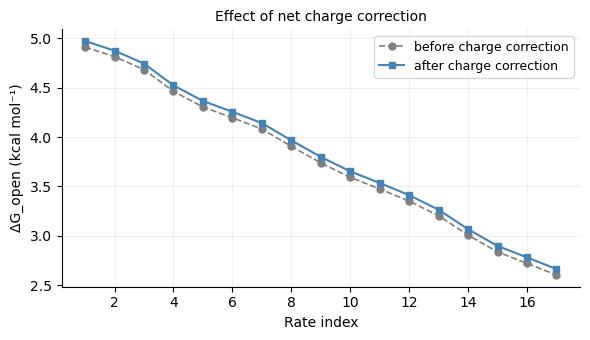

In [28]:
net_charge = fe.net_charge
correction_per_residue = net_charge * (-0.12)   # same shift applied to all residues

print(f"Net charge at pH {PH}: {net_charge:+.2f}")
print(f"Charge correction    : {correction_per_residue:+.3f} kcal/mol per residue")
print(f"  (positive charge → negative correction → lowers apparent ΔG)")

# Show the before/after correction on the sorted dG
dG_no_corr = dG_mean + correction_per_residue   # undo the correction that was already applied

fig, ax = plt.subplots(figsize=(6, 3.5))
x = np.arange(1, n_active + 1)
ax.plot(x, dG_no_corr, 'o--', ms=5, lw=1.2, color='grey',
        label='before charge correction')
ax.plot(x, dG_mean,    's-',  ms=5, lw=1.5, color='steelblue',
        label='after charge correction')
ax.set_xlabel('Rate index', fontsize=10)
ax.set_ylabel('ΔG_open (kcal mol⁻¹)', fontsize=10)
ax.set_title('Effect of net charge correction', fontsize=10)
ax.legend(fontsize=9)
ax.spines[['top','right']].set_visible(False)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. The stability landscape — sorted ΔG plot

The canonical HDX free energy representation plots residues sorted from most to least stable.
The area under the curve (integrated ΔG) is a single-number summary of global stability.

`plot_free_energy()` produces this two-panel figure automatically.

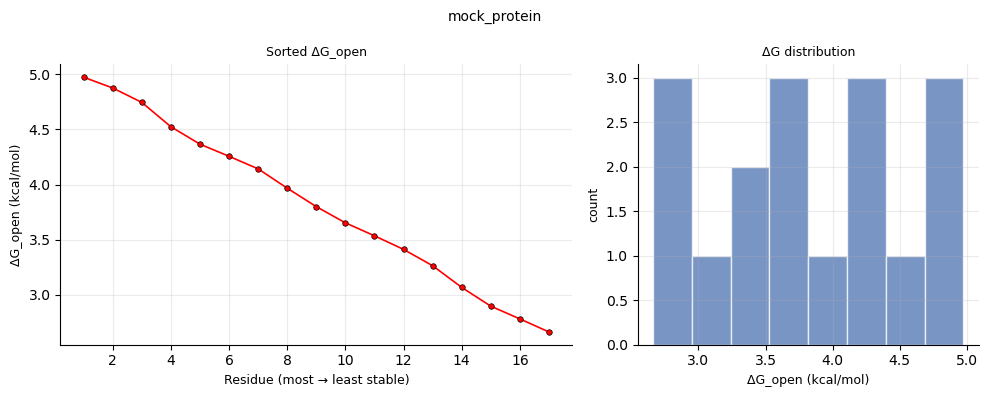

Residues with ΔG > threshold : 17
Most stable   : ΔG = 4.97 kcal/mol
Least stable  : ΔG = 2.66 kcal/mol
Mean ΔG       : 3.82 kcal/mol


In [29]:
fig = hdxrate.plots.plot_free_energy(result)
plt.show()

# Summary statistics
valid_dG = dG_mean[np.isfinite(dG_mean)]
print(f"Residues with ΔG > threshold : {len(fe.dG_sorted)}")
print(f"Most stable   : ΔG = {valid_dG.max():.2f} kcal/mol")
print(f"Least stable  : ΔG = {valid_dG[valid_dG > -2].min():.2f} kcal/mol")
print(f"Mean ΔG       : {valid_dG[valid_dG > -2].mean():.2f} kcal/mol")

## 7. Comparing inferred ΔG to the 'true' value

Because we generated data from known rates, we can compute the ground-truth ΔG and
compare. This is only possible with synthetic data — it validates that the pipeline
is working correctly.

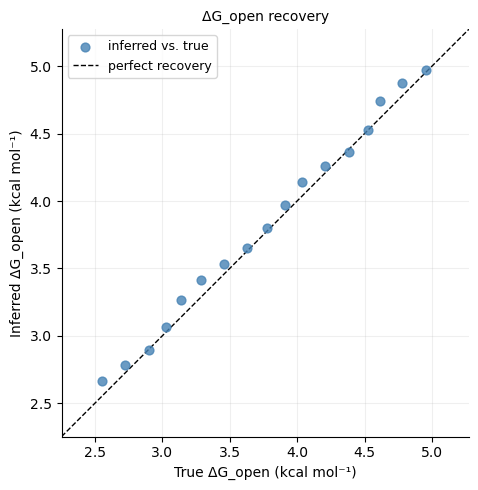

ΔG recovery MAE: 0.062 kcal/mol


In [30]:
from hdxrate.free_energy import dG_from_rates, regression_corrected_intrinsics

R_KCAL = 1.987204e-3

# Compute true dG using the true rates and the same regression-corrected intrinsics
true_rates_linear = np.exp(TRUE_LOG_RATES)   # (N_active,)
true_dG = dG_from_rates(true_rates_linear, fe.reg_intrinsic_rates, TEMPERATURE)

fig, ax = plt.subplots(figsize=(5, 5))
n = min(len(true_dG), len(dG_mean))
finite = np.isfinite(true_dG[:n]) & np.isfinite(dG_mean[:n])

ax.scatter(true_dG[finite], dG_mean[finite],
           s=40, color='steelblue', alpha=0.8, zorder=3,
           label='inferred vs. true')

lim = (min(true_dG[finite].min(), dG_mean[finite].min()) - 0.3,
       max(true_dG[finite].max(), dG_mean[finite].max()) + 0.3)
ax.plot(lim, lim, 'k--', lw=1, label='perfect recovery')

ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('True ΔG_open (kcal mol⁻¹)', fontsize=10)
ax.set_ylabel('Inferred ΔG_open (kcal mol⁻¹)', fontsize=10)
ax.set_title('ΔG_open recovery', fontsize=10)
ax.legend(fontsize=9)
ax.set_aspect('equal')
ax.spines[['top','right']].set_visible(False)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

mae_dG = float(np.mean(np.abs(dG_mean[finite] - true_dG[finite])))
print(f"ΔG recovery MAE: {mae_dG:.3f} kcal/mol")

## Summary

We have covered the complete HDX-MS analysis pipeline:

| Step | Notebook | Key output |
|------|----------|------------|
| Forward model | NB1 | Synthetic mass spectra |
| Bayesian inference | NB2 | Posterior exchange rates |
| Free energies | NB3 | Per-residue ΔG_open |

### Key concepts
- **EX2 regime**: protection factors relate measured and intrinsic exchange rates
- **Milne intrinsics**: sequence/pH/T-dependent reference rates (no free parameters)
- **Regression correction (α=0.38)**: reduces systematic bias from the Milne model
- **Net charge correction**: −0.12 kcal/mol per unit charge
- **Posterior uncertainty**: full propagation from rate → ΔG via MCMC samples

### Using your own data
Replace `generate_mock_rows(...)` with a list of real `InputRow` objects constructed
from your measured m/z and intensity arrays. Everything downstream is identical.